In [1]:
import pandas as pd

train_data = pd.read_csv('train - train.csv')  # Adjust as needed
test_data = pd.read_csv('test - test.csv')  # Adjust as needed

# Basic data exploration
print(train_data.head())
print(train_data.info())


   battery_power  blue  clock_speed  dual_sim    fc  four_g  int_memory  \
0            842     0          2.2         0   1.0     0.0         7.0   
1           1021     1          0.5         1   0.0     1.0        53.0   
2            563     1          0.5         1   2.0     1.0        41.0   
3            615     1          2.5         0   0.0     0.0        10.0   
4           1821     1          1.2         0  13.0     1.0        44.0   

   m_dep  mobile_wt  n_cores  ...  px_height  px_width     ram  sc_h  sc_w  \
0    0.6      188.0      2.0  ...       20.0     756.0  2549.0   9.0   7.0   
1    0.7      136.0      3.0  ...      905.0    1988.0  2631.0  17.0   3.0   
2    0.9      145.0      5.0  ...     1263.0    1716.0  2603.0  11.0   2.0   
3    0.8      131.0      6.0  ...     1216.0    1786.0  2769.0  16.0   8.0   
4    0.6      141.0      2.0  ...     1208.0    1212.0  1411.0   8.0   2.0   

   talk_time  three_g  touch_screen  wifi  price_range  
0         19        0  

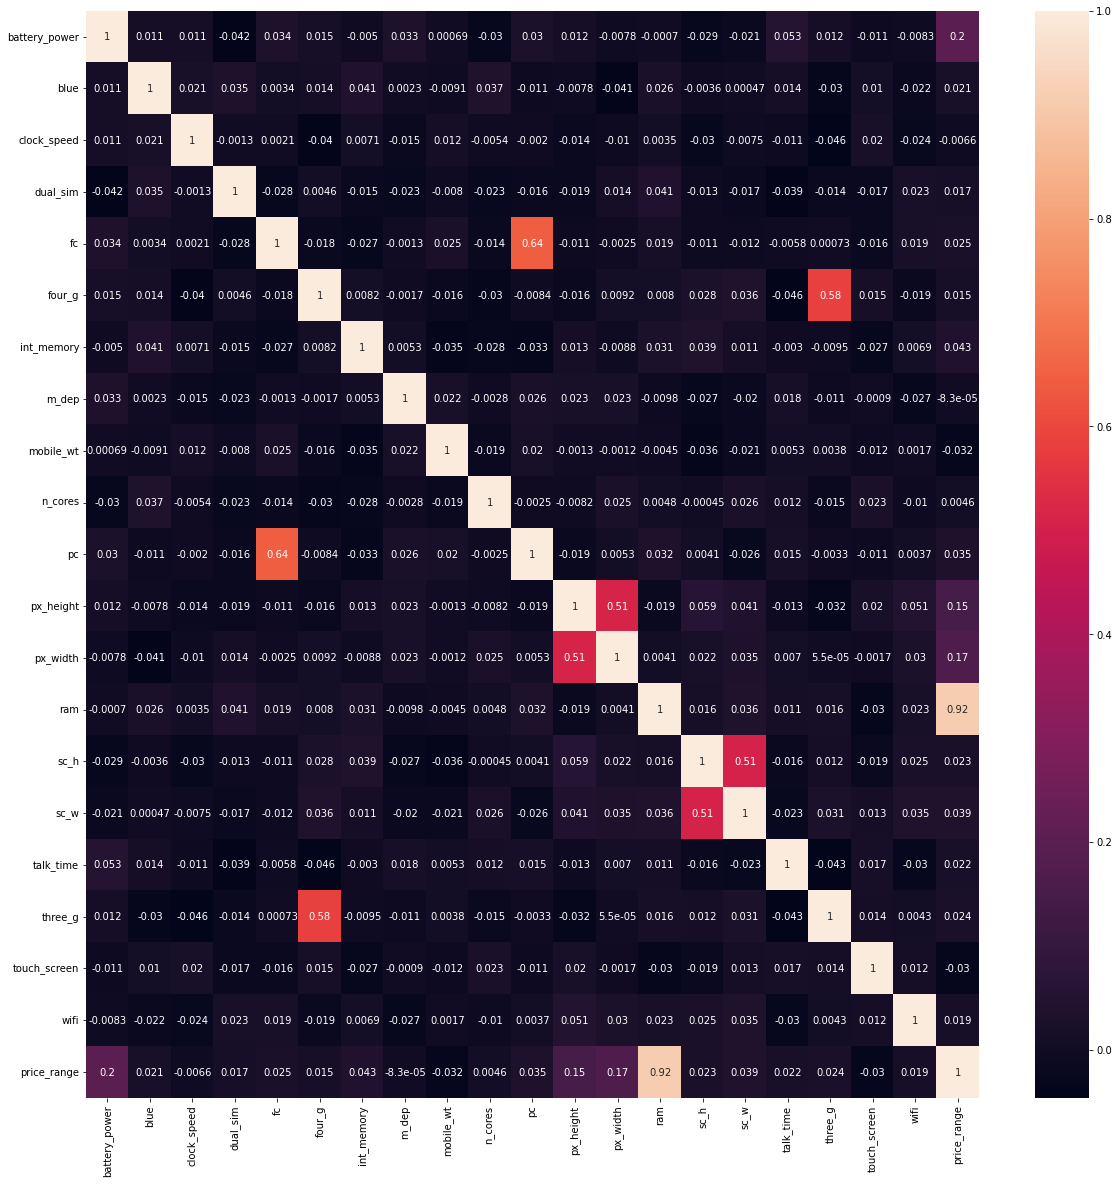

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

# Check correlations
plt.figure(figsize=(20, 20))
correlations = train_data.corr()
sns.heatmap(correlations, annot=True)
plt.show()


In [3]:
train_data.dropna()

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1.0,0.0,7.0,0.6,188.0,2.0,...,20.0,756.0,2549.0,9.0,7.0,19,0,0,1,1
1,1021,1,0.5,1,0.0,1.0,53.0,0.7,136.0,3.0,...,905.0,1988.0,2631.0,17.0,3.0,7,1,1,0,2
2,563,1,0.5,1,2.0,1.0,41.0,0.9,145.0,5.0,...,1263.0,1716.0,2603.0,11.0,2.0,9,1,1,0,2
3,615,1,2.5,0,0.0,0.0,10.0,0.8,131.0,6.0,...,1216.0,1786.0,2769.0,16.0,8.0,11,1,0,0,2
4,1821,1,1.2,0,13.0,1.0,44.0,0.6,141.0,2.0,...,1208.0,1212.0,1411.0,8.0,2.0,15,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,794,1,0.5,1,0.0,1.0,2.0,0.8,106.0,6.0,...,1222.0,1890.0,668.0,13.0,4.0,19,1,1,0,0
1996,1965,1,2.6,1,0.0,0.0,39.0,0.2,187.0,4.0,...,915.0,1965.0,2032.0,11.0,10.0,16,1,1,1,2
1997,1911,0,0.9,1,1.0,1.0,36.0,0.7,108.0,8.0,...,868.0,1632.0,3057.0,9.0,1.0,5,1,1,0,3
1998,1512,0,0.9,0,4.0,1.0,46.0,0.1,145.0,5.0,...,336.0,670.0,869.0,18.0,10.0,19,1,1,1,0


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler

# Select features and target
train_data=train_data.dropna()
features = train_data.drop([ 'price_range'], axis=1)
target = train_data['price_range']

# Standardize features
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(features_scaled, target, test_size=0.2, random_state=42)

# Train Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# Evaluate the model
y_pred = model.predict(X_val)

# Show evaluation metrics
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_pred))
print("Classification Report:")
print(classification_report(y_val, y_pred))


Confusion Matrix:
[[98  8  0  0]
 [ 9 76  4  0]
 [ 0 15 86  6]
 [ 0  0  4 93]]
Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.92      0.92       106
           1       0.77      0.85      0.81        89
           2       0.91      0.80      0.86       107
           3       0.94      0.96      0.95        97

    accuracy                           0.88       399
   macro avg       0.88      0.89      0.88       399
weighted avg       0.89      0.88      0.88       399



In [5]:
import joblib
joblib.dump(model, 'device_price_predictor.joblib')

['device_price_predictor.joblib']

In [6]:
from fastapi import FastAPI
